In [1]:
import geopandas as gpd
import numpy as np
import rasterio
from rasterstats import zonal_stats
import glob
import pandas as pd
import os
from datetime import datetime
import re
import matplotlib.pyplot as plt
from exactextract import exact_extract
import seaborn as sns
import statsmodels.api as sm

In [4]:
grid = gpd.read_file(
    "C:/Floor/Documenten/ENV-year-2/Thesis/Data/Schildersbuurt/master_grid_schildersbuurt.gpkg",
    layer="master_grid_with_features",
)

# Reproject to EPSG:28992 (RD New - meters) so calculations work properly
grid = grid.to_crs("EPSG:28992")

print(grid.geometry.area[120:130])  # Check area of grid cells in square meters


120    397.447947
121    397.447933
122    397.447918
123    397.447903
124    397.447888
125    397.447873
126    397.447859
127    397.447844
128    397.447829
129    397.447814
dtype: float64


--- Spearman Correlatie Matrijs ---
                            LST_2025-06-02 13:54  boomkroonvolume_m3  \
LST_2025-06-02 13:54                    1.000000           -0.229936   
boomkroonvolume_m3                     -0.229936            1.000000   
boomkroonoppervlakte_m2                -0.230845            0.990479   
biomassa_bermudez_kg                   -0.230846            0.996098   
percentage_green_shadow                -0.191926            0.870583   
percentage_grey_shadow                  0.102713           -0.190382   
percentage_combined_shadow             -0.121724            0.492372   
percentage_onverhard                   -0.273115            0.328837   
percentage_verharding                   0.267172           -0.330326   
percentage_water                        0.015878            0.067116   

                            boomkroonoppervlakte_m2  biomassa_bermudez_kg  \
LST_2025-06-02 13:54                      -0.230845             -0.230846   
boomkroonvolume_m

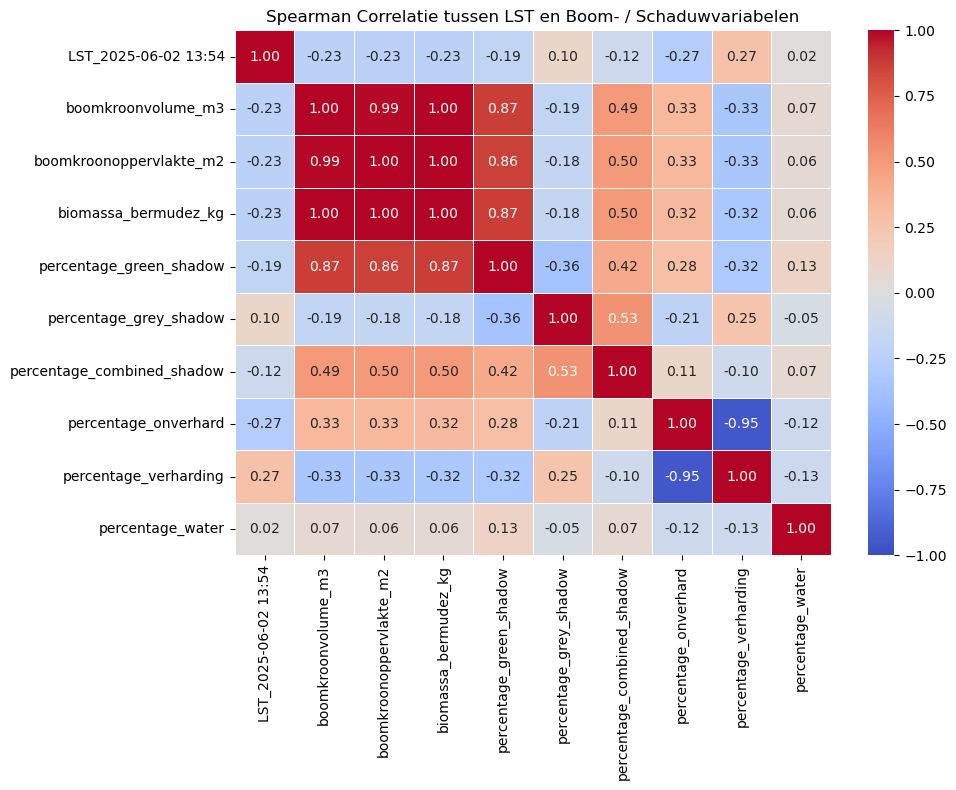

In [5]:
# 2. Selecteer alleen de kolommen die je wilt meenemen in je correlatie-analyse
# (Pas de kolomnamen hieronder eventueel exact aan aan wat in je attribuuttabel staat)
vars_to_correlate = [
    "LST_2025-06-02 13:54",  # Je LST variabele
    "boomkroonvolume_m3",
    "boomkroonoppervlakte_m2",
    "biomassa_bermudez_kg",
    "percentage_green_shadow",
    "percentage_grey_shadow",
    "percentage_combined_shadow",
    "percentage_onverhard",
    "percentage_verharding",
    "percentage_water"
    # Voeg hier eventueel verhard/onverhard toe als je die kolommen hebt
]

# Maak een schone DataFrame van deze kolommen
df_stats = grid[vars_to_correlate].copy()

# 3. Bereken de Spearman-correlatiematrix (sterk aanbevolen voor niet-normale/niet-lineaire data)
spearman_corr = df_stats.corr(method="spearman")

print("--- Spearman Correlatie Matrijs ---")
print(spearman_corr)

# 4. Optioneel: Maak er een mooi visueel hittekaartje (heatmap) van voor je thesis
plt.figure(figsize=(10, 8))
sns.heatmap(
    spearman_corr,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f",
    linewidths=0.5,
)
plt.title("Spearman Correlatie tussen LST en Boom- / Schaduwvariabelen")
plt.tight_layout()
plt.show()

In [11]:
cols_to_use = [
    "LST_2025-06-02 13:54",  # Afhankelijke variabele (Y)
    "boomkroonvolume_m3",  # Onafhankelijke variabele (X)
    "percentage_green_shadow",  # Onafhankelijke variabele (X)
    "percentage_verharding",  # Onafhankelijke variabele (X)
    "percentage_water",  # Onafhankelijke variabele (X)
]

# Maak een schone subset en gooi lege rijen (NaNs) weg
df_reg = grid[cols_to_use].dropna()

# 3. Splits in Y (wat je wilt verklaren) en X (de voorspellers)
y = df_reg["LST_2025-06-02 13:54"]
X = df_reg[
    [
        "boomkroonvolume_m3",
        "percentage_green_shadow",
        "percentage_verharding",
        "percentage_water",
    ]
]

# 4. Voeg een constante (intercept) toe aan het model
X = sm.add_constant(X)

# 5. Fit het Ordinary Least Squares (OLS) regressiemodel
model = sm.OLS(y, X).fit()

# 6. Print de volledige statistische samenvatting
print(model.summary())

                             OLS Regression Results                             
Dep. Variable:     LST_2025-06-02 13:54   R-squared:                       0.135
Model:                              OLS   Adj. R-squared:                  0.134
Method:                   Least Squares   F-statistic:                     151.8
Date:                  Wed, 21 Oct 2026   Prob (F-statistic):          8.75e-121
Time:                          11:12:47   Log-Likelihood:                -5384.1
No. Observations:                  3886   AIC:                         1.078e+04
Df Residuals:                      3881   BIC:                         1.081e+04
Df Model:                             4                                         
Covariance Type:              nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------
const 

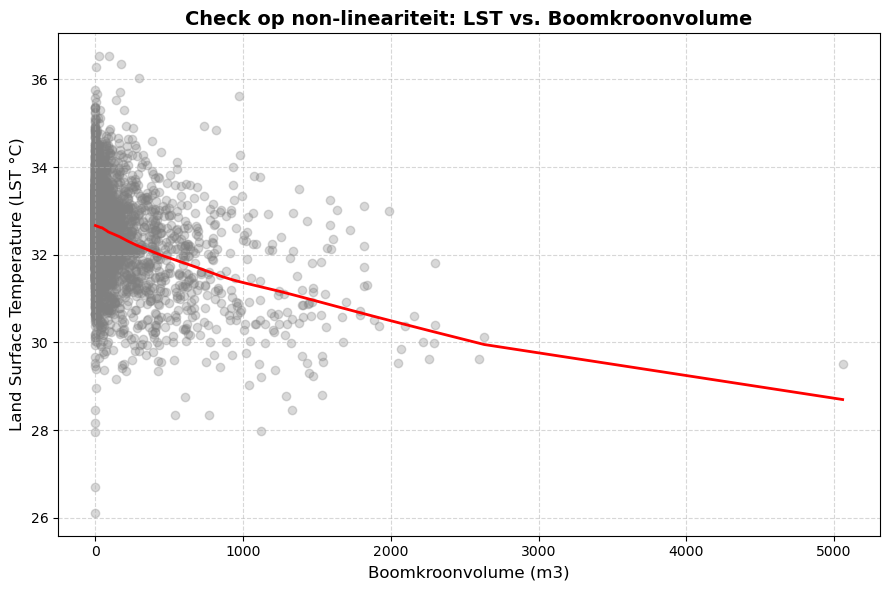

In [15]:
plt.figure(figsize=(9, 6))

sns.regplot(
    x="boomkroonvolume_m3",
    y="LST_2025-06-02 13:54",
    data=grid,
    scatter_kws={
        "alpha": 0.3,
        "color": "gray",
    },  # Maakt de punten transparant zodat overlappingen zichtbaar zijn
    line_kws={
        "color": "red",
        "linewidth": 2,
    },  # De trendlijn in het rood
    lowess=True,  # Dit zorgt voor een vloeiende, non-lineaire lijn!
)

# 3. Layout en labels toevoegen
plt.title(
    "Check op non-lineariteit: LST vs. Boomkroonvolume",
    fontsize=14,
    weight="bold",
)
plt.xlabel("Boomkroonvolume (m3)", fontsize=12)
plt.ylabel("Land Surface Temperature (LST °C)", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

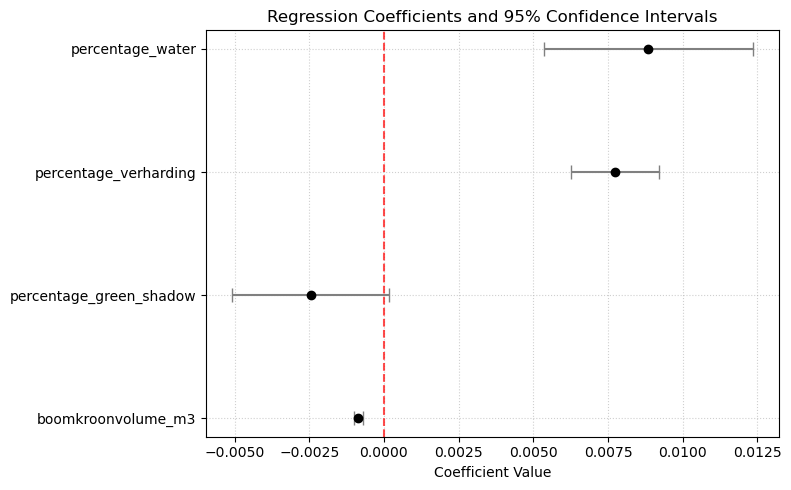

In [12]:
import matplotlib.pyplot as plt
import pandas as pd

# Assuming 'model' is your fitted OLS model from statsmodels
params = model.params.drop("const")  # Remove intercept for scaling
conf = model.conf_int().drop("const")
conf.columns = ["Lower", "Upper"]
conf["Coef"] = params

# Plotting
plt.figure(figsize=(8, 5))
plt.errorbar(
    conf["Coef"],
    conf.index,
    xerr=[conf["Coef"] - conf["Lower"], conf["Upper"] - conf["Coef"]],
    fmt="o",
    color="black",
    ecolor="gray",
    capsize=5,
)
plt.axvline(0, color="red", linestyle="--", alpha=0.7)  # Zero-effect line
plt.title("Regression Coefficients and 95% Confidence Intervals")
plt.xlabel("Coefficient Value")
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()

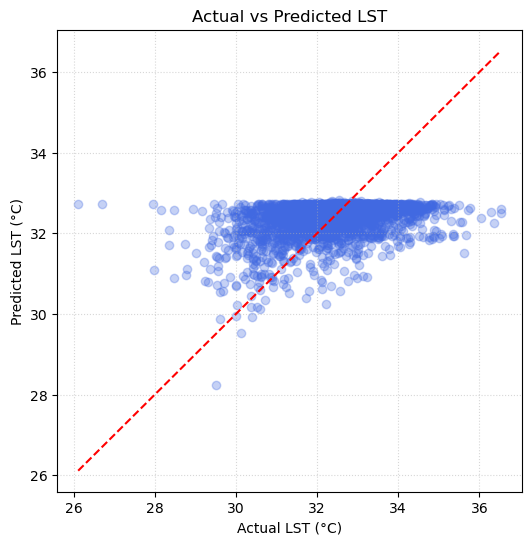

In [13]:
plt.figure(figsize=(6, 6))
plt.scatter(y, model.fittedvalues, alpha=0.3, color="royalblue")
plt.plot(
    [y.min(), y.max()], [y.min(), y.max()], color="red", linestyle="--"
)  # 1:1 line
plt.xlabel("Actual LST (°C)")
plt.ylabel("Predicted LST (°C)")
plt.title("Actual vs Predicted LST")
plt.grid(True, linestyle=":", alpha=0.5)
plt.show()

Random Forest R-squared: 0.834

Belangrijkste variabelen (Feature Importance):
- boomkroonvolume_m3: 0.354
- percentage_grey_shadow: 0.297
- percentage_verharding: 0.349


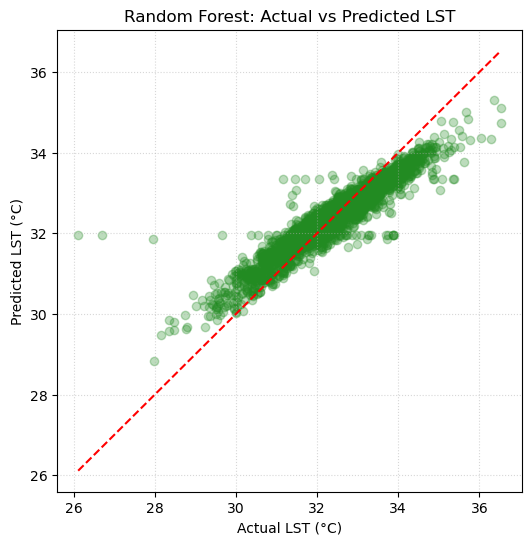

In [15]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score

# 1. Selecteer dezelfde variabelen als je OLS-model en verwijder missende waarden
features = [
    "boomkroonvolume_m3",
    "percentage_grey_shadow",
    "percentage_verharding",
]
df_rf = grid[features + ["LST_2025-06-02 13:54"]].dropna()

X = df_rf[features]
y = df_rf["LST_2025-06-02 13:54"]

# 2. Train het Random Forest model
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X, y)
y_pred = rf_model.predict(X)

# 3. Print de R-squared en Feature Importances
print(f"Random Forest R-squared: {r2_score(y, y_pred):.3f}")
print("\nBelangrijkste variabelen (Feature Importance):")
for name, importance in zip(features, rf_model.feature_importances_):
  print(f"- {name}: {importance:.3f}")

# 4. Maak de Actual vs Predicted grafiek voor Random Forest
plt.figure(figsize=(6, 6))
plt.scatter(y, y_pred, alpha=0.3, color="forestgreen")
plt.plot(
    [y.min(), y.max()], [y.min(), y.max()], color="red", linestyle="--"
)  # 1:1 lijn
plt.xlabel("Actual LST (°C)")
plt.ylabel("Predicted LST (°C)")
plt.title("Random Forest: Actual vs Predicted LST")
plt.grid(True, linestyle=":", alpha=0.5)
plt.show()

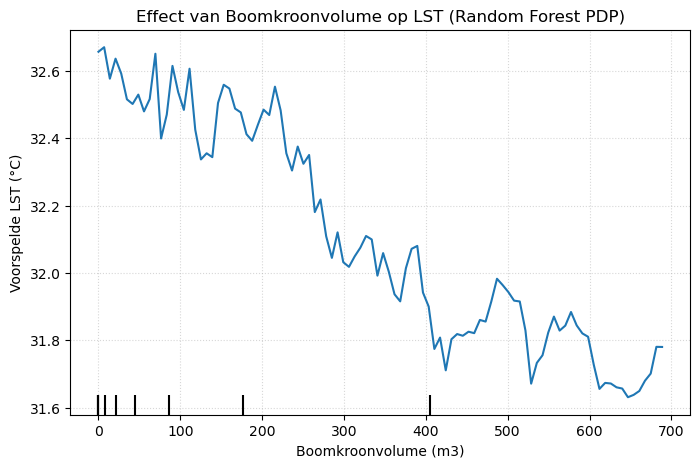

In [18]:
import matplotlib.pyplot as plt
from sklearn.inspection import PartialDependenceDisplay

# Maak een Partial Dependence Plot voor boomkroonvolume
fig, ax = plt.subplots(figsize=(8, 5))
PartialDependenceDisplay.from_estimator(
    rf_model, X, features=["boomkroonvolume_m3"], ax=ax
)

plt.title("Effect van Boomkroonvolume op LST (Random Forest PDP)")
plt.ylabel("Voorspelde LST (°C)")
plt.xlabel("Boomkroonvolume (m3)")
plt.grid(True, linestyle=":", alpha=0.5)
plt.show()

LinearGAM                                                                                                 
=============================================== ==========================================================
Distribution:                        NormalDist Effective DoF:                                     38.7077
Link Function:                     IdentityLink Log Likelihood:                                 -5310.1541
Number of Samples:                         3886 AIC:                                            10699.7235
                                                AICc:                                           10700.5643
                                                GCV:                                                 0.926
                                                Scale:                                              0.9536
                                                Pseudo R-Squared:                                   0.1676
Feature Function                  Lam

C:\Users\hoeks\AppData\Local\Temp\ipykernel_13432\2159162624.py:21: UserWarning: KNOWN BUG: p-values computed in this summary are likely much smaller than they should be. 
 
Please do not make inferences based on these values! 

Collaborate on a solution, and stay up to date at: 
github.com/dswah/pyGAM/issues/163 

  gam.summary()


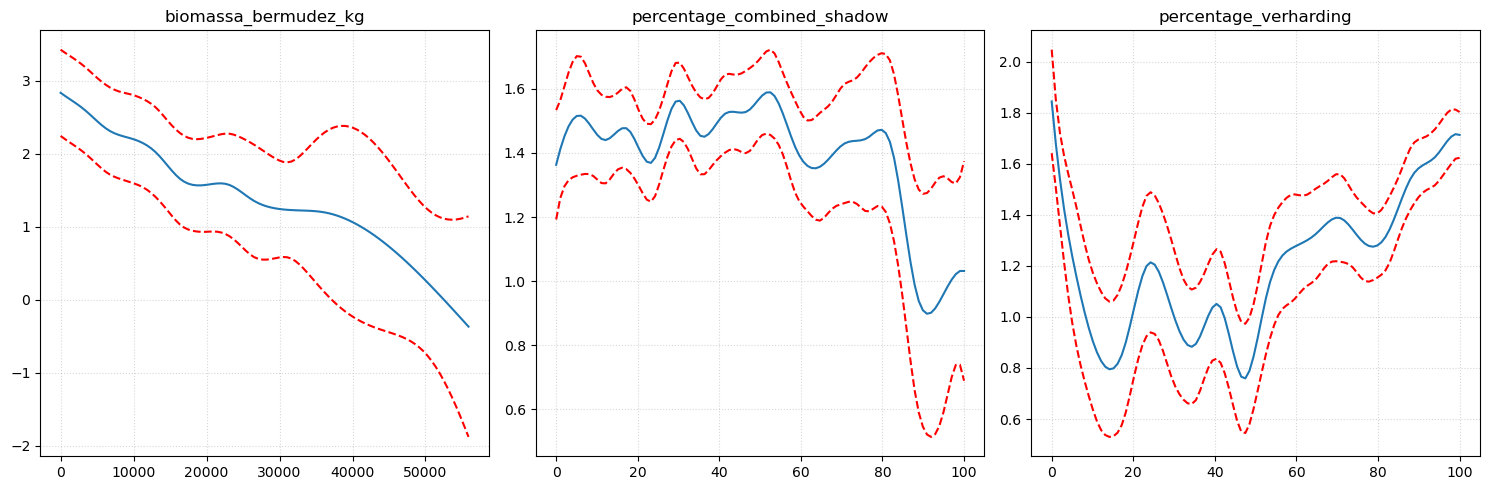

In [28]:
from pygam import LinearGAM, s
import matplotlib.pyplot as plt
import pandas as pd

# 1. Selecteer je data en haal missende waardes weg
features = [
    "biomassa_bermudez_kg",
    "percentage_combined_shadow",
    "percentage_verharding",
]
df_gam = grid[features + ["LST_2025-06-02 13:54"]].dropna()

X = df_gam[features].values
y = df_gam["LST_2025-06-02 13:54"].values

# 2. Bouw het GAM-model
# De 's()' functie geeft aan dat het model een vloeiende curve (spline) mag tekenen voor die variabele
gam = LinearGAM(s(0) + s(1) + s(2)).fit(X, y)

# 3. Bekijk de statistische samenvatting
gam.summary()

# 3. Visualiseer de curves per variabele
fig, axs = plt.subplots(1, 3, figsize=(15, 5))
titles = features  # Gebruik de feature namen als titels voor de subplots

for i, ax in enumerate(axs):
  # Genereer de grid voor deze specifieke term
  XX = gam.generate_X_grid(term=i)

  # Plot de hoofdcurve (partial dependence)
  ax.plot(XX[:, i], gam.partial_dependence(term=i, X=XX))

  # GEWIJZIGD: Gebruik width=0.95 in plaats van 95 voor het 95% betrouwbaarheidsinterval
  ax.plot(
      XX[:, i],
      gam.partial_dependence(term=i, X=XX, width=0.95)[1],
      c="r",
      ls="--",
  )

  ax.title.set_text(titles[i])
  ax.grid(True, linestyle=":", alpha=0.5)

plt.tight_layout()
plt.show()